In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline


sales = pd.read_csv("Product-Sales-Region.csv")

sales.head()

,Date,Region,Product,Quantity,UnitPrice,StoreLocation,CustomerType,Discount,Salesperson,TotalPrice,PaymentMethod,Promotion,Returned,OrderID,CustomerName,ShippingCost,OrderDate,DeliveryDate,RegionManager
0,02/23/2023,East,Laptop,14,163.60,Store B,Wholesale,0.00,Eva,2290.400,Online,FREESHIP,0,REG100000,Cust 6583,43.34,02/23/2023,02/27/2023,Eric
1,12/19/2024,South,Phone,1,544.01,Store A,Retail,0.00,Alice,544.010,Gift Card,SAVE10,0,REG100001,Cust 2144,5.30,12/19/2024,12/28/2024,Sophie
2,05/10/2023,North,Desk,14,346.18,Store B,Wholesale,0.10,Alice,4361.868,Online,WINTER15,0,REG100002,Cust 5998,20.46,05/10/2023,05/19/2023,Ryan
3,02/26/2025,Central,Chair,18,384.82,Store A,Wholesale,0.15,Frank,5887.746,Gift Card,FREESHIP,0,REG100003,Cust 7136,27.95,02/26/2025,03/02/2025,Cameron
4,06/24/2023,East,Desk,18,237.76,Store C,Retail,0.00,Carlos,4279.680,Online,SAVE10,0,REG100004,Cust 6506,5.73,06/24/2023,06/27/2023,Eric


<Axes: xlabel='Product'>

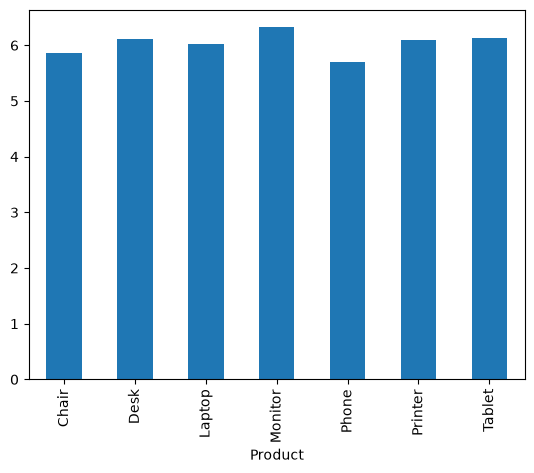

In [15]:
col_to_select = ["Region", "Product",	"Quantity",	"UnitPrice", "StoreLocation" , "CustomerType",	"TotalPrice", "ShippingCost",	"OrderDate",	"DeliveryDate"]
sales= sales.loc[:,col_to_select]

sales["OrderDate"] = pd.to_datetime(sales["OrderDate"])
sales["DeliveryDate"] = pd.to_datetime(sales["DeliveryDate"])

deliveryTime = (
    sales["DeliveryDate"] - sales["OrderDate"]
).dt.days

new_sales = pd.DataFrame({
    'Region': sales["Region"], 
    'Product': sales["Product"], 
    'Quantity': sales["Quantity"],  
    'StoreLocation': sales["StoreLocation"], 
    'CustomerType': sales["CustomerType"],
    'TotalPrice': sales["TotalPrice"],
    'ShippingCost': sales["ShippingCost"],
    'DeliveryTime': deliveryTime})

y = new_sales["DeliveryTime"]

X = new_sales[[
    "Region",
    "Product",
    "StoreLocation",
    "CustomerType",
    "Quantity",
    "TotalPrice",
    "ShippingCost"
]]

X_encoded = pd.get_dummies(
    X,
    columns=["Region", "StoreLocation", "CustomerType","Product"],
    drop_first=True
)

#drop first removes redundant dummy columns


new_sales.groupby('Product')['DeliveryTime'].mean().plot(kind='bar')


In [20]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.33)

In [24]:
model = LinearRegression()
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test,y_pred))
print(f'RMSE: {rmse:3.3} ({rmse/np.mean(y_pred)*100:3.3}%)')

score = model.score(X_train,y_train)
print('Model determination: ', score)

coefficients = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Coefficient": model.coef_
})

print(
    coefficients.sort_values(
        "Coefficient",
        ascending=False
    )
)

RMSE: 2.58 (42.6%)
Model determination:  0.019691246286584363
                   Feature  Coefficient
4             Region_North     0.538316
13         Product_Monitor     0.465209
16          Product_Tablet     0.315032
8    StoreLocation_Store C     0.283255
3              Region_East     0.228428
11            Product_Desk     0.199384
6              Region_West     0.097469
15         Product_Printer     0.083973
12          Product_Laptop     0.081498
14           Product_Phone     0.049858
1               TotalPrice     0.000021
10  CustomerType_Wholesale    -0.003672
2             ShippingCost    -0.009933
0                 Quantity    -0.019006
5             Region_South    -0.061778
7    StoreLocation_Store B    -0.083789
9    StoreLocation_Store D    -0.113943


In [26]:
pipeline = make_pipeline(PolynomialFeatures(2), LinearRegression())
pipeline.fit(X_train,y_train)

pred = pipeline.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test,pred))
print(f'RMSE: {rmse:3.3} ({rmse/np.mean(pred)*100:3.3}%)')

score = pipeline.score(X_train,y_train)
print('Model determination: ', score)


RMSE: 2.63 (43.3%)
Model determination:  0.032166633568230796
